This notebook shows the discrimination power of the likelihood metric against the current chi2 at particle identification

In [1]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
# from analysis_village.plot_style import sbnd_style

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)



In [2]:
with pd.HDFStore("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_collab_LL.df", mode="r") as store:
    keys = store.keys()
    print(keys)

['/evt_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/mcnu_0', '/pot_0', '/split']


In [14]:
df = pd.read_hdf("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_largeTest_LL.df", key='/evt_0')
# # df = df[df["total_nhits_proton"] > 14]
# muondf = df[np.abs(df["truth_pdg"]) == 13]
# piondf = df[np.abs(df["truth_pdg"]) == 211]
# protondf = df[df["truth_pdg"] == 2212]
df = df[df["slc", "is_clear_cosmic"] == 0]
df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


/tmp/ipykernel_1150730/3408046138.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["slc", "is_clear_cosmic"] == 0]
/tmp/ipykernel_1150730/3408046138.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


In [3]:
df.head()

slc  \
                                                      is_clear_cosmic   
                                                                        
                                                                        
                                                                        
                                                                        
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                   
1        1     0              0                                     0   
                              1                                     0   
         3     0              0                                     0   
                              1                                     0   
         4     0              0                                     0   

                                                                              \
                                                          vertex               
                                                               x           y   
                                                                               
                                                                               
                                                                               
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                          
1        1     0              0                       -68.975815  124.859596   
                              1                       -68.975815  124.859596   
         3     0              0                       -52.697365    4.298021   
                              1                       -52.697365    4.298021   
         4     0              0                       -46.268570 -186.258606   

                                                                        \
                                                                  self   
                                                                z        
                                                                         
                                                                         
                                                                         
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                    
1        1     0              0                        217.167191   73   
                              1                        217.167191   73   
         3     0              0                        399.908264   28   
                              1                        399.908264   28   
         4     0              0                        148.239227   39   

                                                                               \
                                                         tmatch                 
                                                            eff       pur idx   
                                                                                
                                                                                
                                                                                
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                           
1        1     0              0                        0.980509  0.560783   0   
                              1                        0.980509  0.560783   0   
         3     0              0                        0.656768  0.876566   1   
                              1                        0.656768  0.876566   1   
         4     0              0                        0.967384  0.665963   0   

                                                                              \
                                                      producer          nuid   
                                                               crlongtrkdiry   
                                                                               
                                              

In [15]:
p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")


Protons: 7086, Muons: 1789, Pions: 942


/tmp/ipykernel_1150730/556601378.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
/tmp/ipykernel_1150730/556601378.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
/tmp/ipykernel_1150730/556601378.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]


/tmp/ipykernel_1150730/3593872833.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:12: PerformanceWarning: indexing past lexsort depth may impact perfor

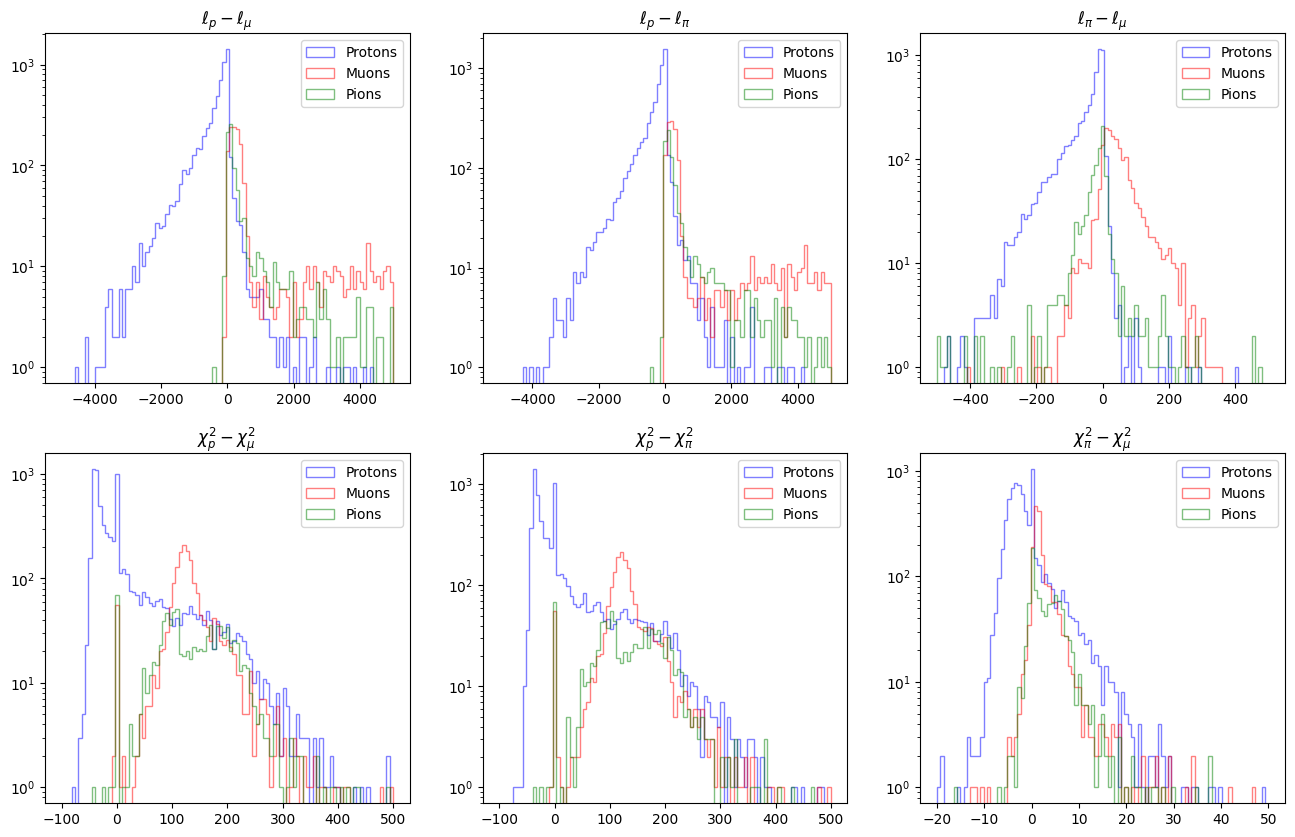

In [17]:
fig, ax = plt.subplots(2,3, figsize=(16, 10))
ax = ax.flatten()
log=True

ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[0].legend()
ax[0].set_title(f"$\ell_p - \ell_\mu$ ")


ax[1].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[1].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[1].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[1].legend()
ax[1].set_title(f"$\ell_p - \ell_\pi$ ")


ax[2].hist(p_df["pfp", "trk", "llpid", "ell_pi"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[2].hist(mu_df["pfp", "trk", "llpid", "ell_pi"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[2].hist(pi_df["pfp", "trk", "llpid", "ell_pi"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[2].legend()
ax[2].set_title(f"$\ell_\pi - \ell_\mu$ ")


ax[3].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[3].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[3].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[3].legend()
ax[3].set_title(f"$\chi^2_p - \chi^2_\mu$ ")

ax[4].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[4].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[4].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[4].legend()
ax[4].set_title(f"$\chi^2_p - \chi^2_\pi$ ")

ax[5].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[5].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[5].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[5].legend()
ax[5].set_title(f"$\chi^2_\pi - \chi^2_\mu$ ")

if log:
    for i in range(6):
        ax[i].set_yscale('log')
plt.show()  

/tmp/ipykernel_1150730/2263204449.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
/tmp/ipykernel_1150730/2263204449.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
/tmp/ipykernel_1150730/2263204449.py:14: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
/tmp/ipykernel_1150730/2263204449.py:19: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2

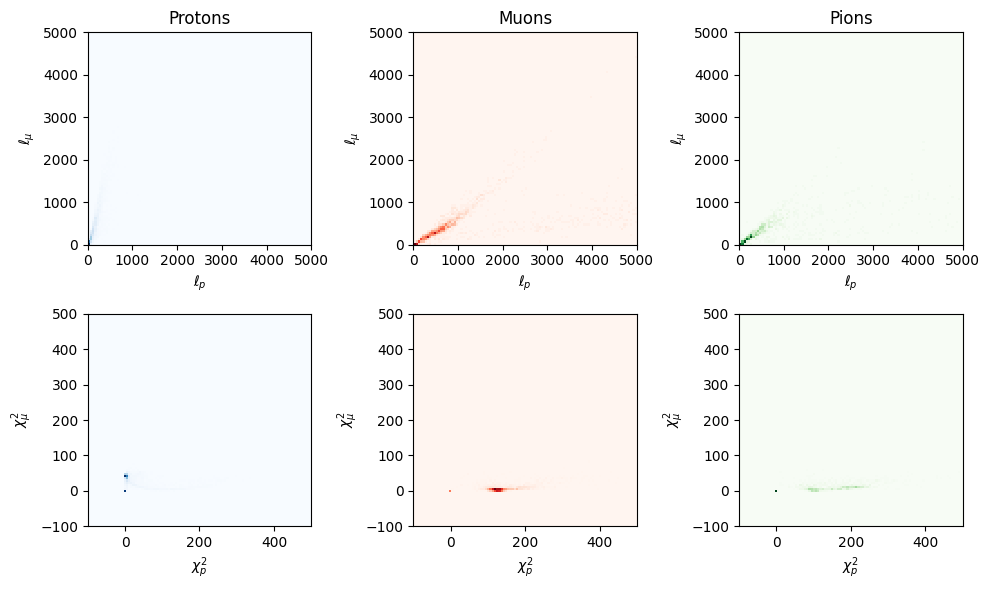

In [18]:
fig, ax = plt.subplots(2,3,figsize=(10, 6))
ax=ax.flatten()

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")
ax[0].set_title("Protons")

ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
ax[1].set_xlabel("$\ell_p$")
ax[1].set_ylabel("$\ell_\mu$")
ax[1].set_title("Muons")

ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
ax[2].set_xlabel("$\ell_p$")
ax[2].set_ylabel("$\ell_\mu$")
ax[2].set_title("Pions")

ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Blues')
ax[3].set_xlabel("$\chi^2_p$")
ax[3].set_ylabel("$\chi^2_\mu$")

ax[4].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Reds')
ax[4].set_xlabel("$\chi^2_p$")
ax[4].set_ylabel("$\chi^2_\mu$")
ax[5].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Greens')
ax[5].set_xlabel("$\chi^2_p$")
ax[5].set_ylabel("$\chi^2_\mu$")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1150730/1689864628.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:15: PerformanceWarning: indexing past lexsort depth may impact

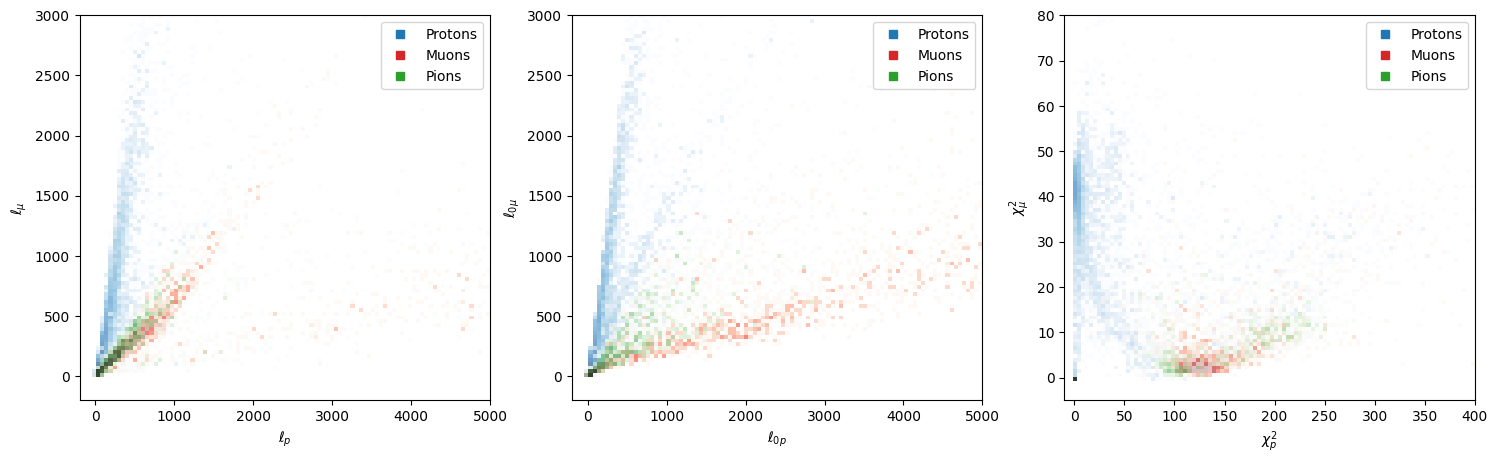

In [19]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1,3,figsize=(18, 5))

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].plot([], [], 's', color='tab:blue', label='Protons')
ax[0].plot([], [], 's', color='tab:red', label='Muons')
ax[0].plot([], [], 's', color='tab:green', label='Pions')
ax[0].legend()
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")

ax[1].hist2d(p_df["pfp", "trk", "llpid", "ell0_p"], p_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell0_p"], mu_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(pi_df["pfp", "trk", "llpid", "ell0_p"], pi_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].plot([], [], 's', color='tab:blue', label='Protons')
ax[1].plot([], [], 's', color='tab:red', label='Muons')
ax[1].plot([], [], 's', color='tab:green', label='Pions')
ax[1].legend()
ax[1].set_xlabel("$\ell_{0p}$")
ax[1].set_ylabel("$\ell_{0\mu}$")


ax[2].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].plot([], [], 's', color='tab:blue', label='Protons')
ax[2].plot([], [], 's', color='tab:red', label='Muons')
ax[2].plot([], [], 's', color='tab:green', label='Pions')
ax[2].legend()
ax[2].set_xlabel("$\chi^2_p$")
ax[2].set_ylabel("$\chi^2_\mu$")

# plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1937425854.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
/tmp/ipykernel_1150730/1937425854.py:10: PerformanceWarning: indexing past lexsort depth may impact perform

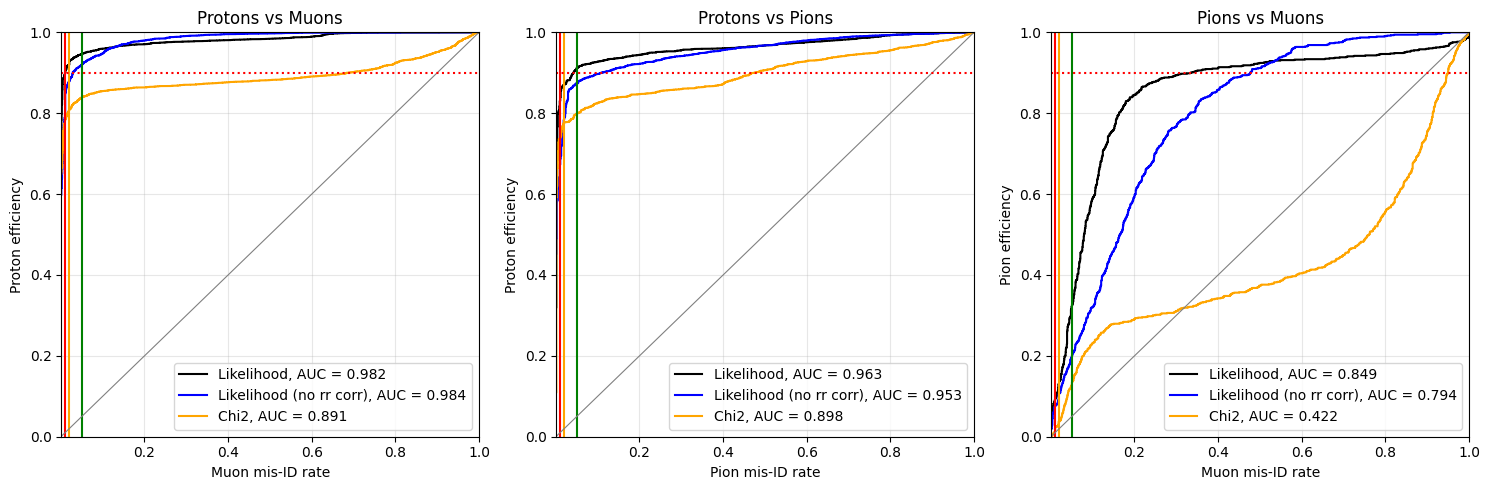

In [30]:
# only keep tracks where both the likelihood and the chi2 worked
p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]

fig, ax = plt.subplots(1,3,figsize=(15, 5))

# Protons vs Muons, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_p"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
# Protons vs Muons, likelihood0
sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_p"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Muons, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[0].set_title("Protons vs Muons")
ax[0].set_xlabel("Muon mis-ID rate")
ax[0].set_ylabel("Proton efficiency")
ax[0].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])


# Protons vs Pions, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell_p"] - pi_ok["pfp", "trk", "llpid", "ell_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell0_p"] - pi_ok["pfp", "trk", "llpid", "ell0_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Pions, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
bkg = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[1].set_title("Protons vs Pions")
ax[1].set_xlabel("Pion mis-ID rate")
ax[1].set_ylabel("Proton efficiency")
ax[1].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

# Pions vs Muons, likelihood
sig = pi_ok["pfp", "trk", "llpid", "ell_pi"] - pi_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_pi"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = pi_ok["pfp", "trk", "llpid", "ell0_pi"] - pi_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_pi"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Pions vs Muons, chi2
sig = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[2].set_title("Pions vs Muons")
ax[2].set_xlabel("Muon mis-ID rate")
ax[2].set_ylabel("Pion efficiency")
ax[2].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

for k in range(3):
    ax[k].plot([0, 1], [0, 1], color='gray', linewidth=0.8)
    ax[k].axhline(0.9, color='red', linestyle=':')
    ax[k].set_xlim(0.001, 1)
    # ax[k].set_xscale("log")
    ax[k].set_ylim(0, 1)
    ax[k].grid(alpha=0.3)
    ax[k].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1530449805.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_chi_

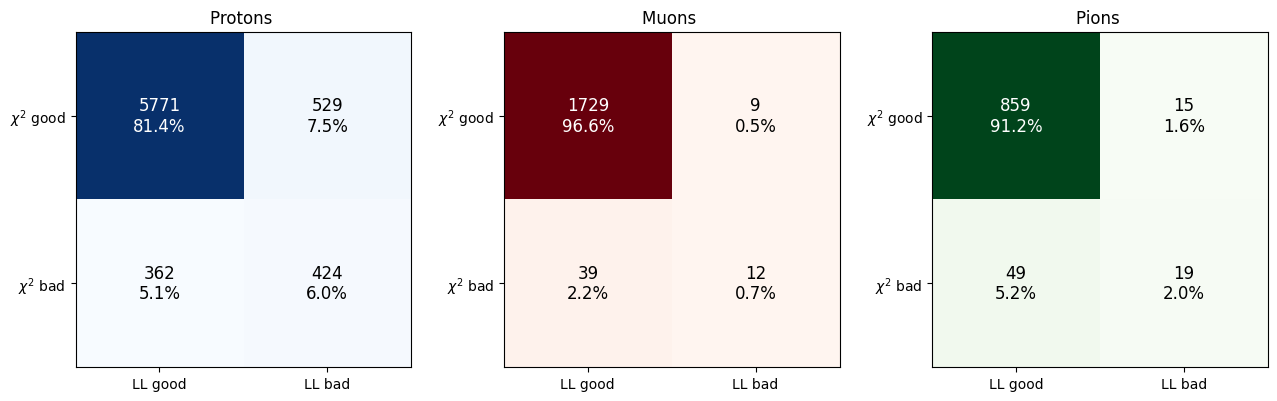

In [31]:
# True = that PID failed for this track
p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
pi_chi_bad = pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0

# rows = chi2 (good, bad), columns = llpid (good, bad)
p_mat  = np.array([[np.sum(~p_chi_bad & ~p_ll_bad),   np.sum(~p_chi_bad & p_ll_bad)],
                   [np.sum(p_chi_bad & ~p_ll_bad),    np.sum(p_chi_bad & p_ll_bad)]])
mu_mat = np.array([[np.sum(~mu_chi_bad & ~mu_ll_bad), np.sum(~mu_chi_bad & mu_ll_bad)],
                   [np.sum(mu_chi_bad & ~mu_ll_bad),  np.sum(mu_chi_bad & mu_ll_bad)]])
pi_mat = np.array([[np.sum(~pi_chi_bad & ~pi_ll_bad), np.sum(~pi_chi_bad & pi_ll_bad)],
                   [np.sum(pi_chi_bad & ~pi_ll_bad),  np.sum(pi_chi_bad & pi_ll_bad)]])

fig, ax = plt.subplots(1,3,figsize=(13, 4))

ax[0].imshow(p_mat, cmap='Blues')
ax[0].set_title(f"Protons ")
ax[1].imshow(mu_mat, cmap='Reds')
ax[1].set_title(f"Muons ")
ax[2].imshow(pi_mat, cmap='Greens')
ax[2].set_title(f"Pions ")

for k, mat in enumerate([p_mat, mu_mat, pi_mat]):
    for i in range(2):
        for j in range(2):
            ax[k].text(j, i, f"{mat[i, j]}\n{100 * mat[i, j] / mat.sum():.1f}%", ha='center', va='center', fontsize=12, color='white' if mat[i, j] > mat.max() / 2 else 'black')
    ax[k].set_xticks([0, 1])
    ax[k].set_xticklabels(["LL good", "LL bad"])
    ax[k].set_yticks([0, 1])
    ax[k].set_yticklabels(["$\\chi^2$ good", "$\\chi^2$ bad"])

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/2452625986.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]
/tmp/ipykernel_1150730/2452625986.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV
/tmp/ipykernel_1150730/2452625986.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
/tmp/ipykernel_1150730/2452625986.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/2452625986.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = p_cont["pfp", "trk", "truth", "p", "end_process"

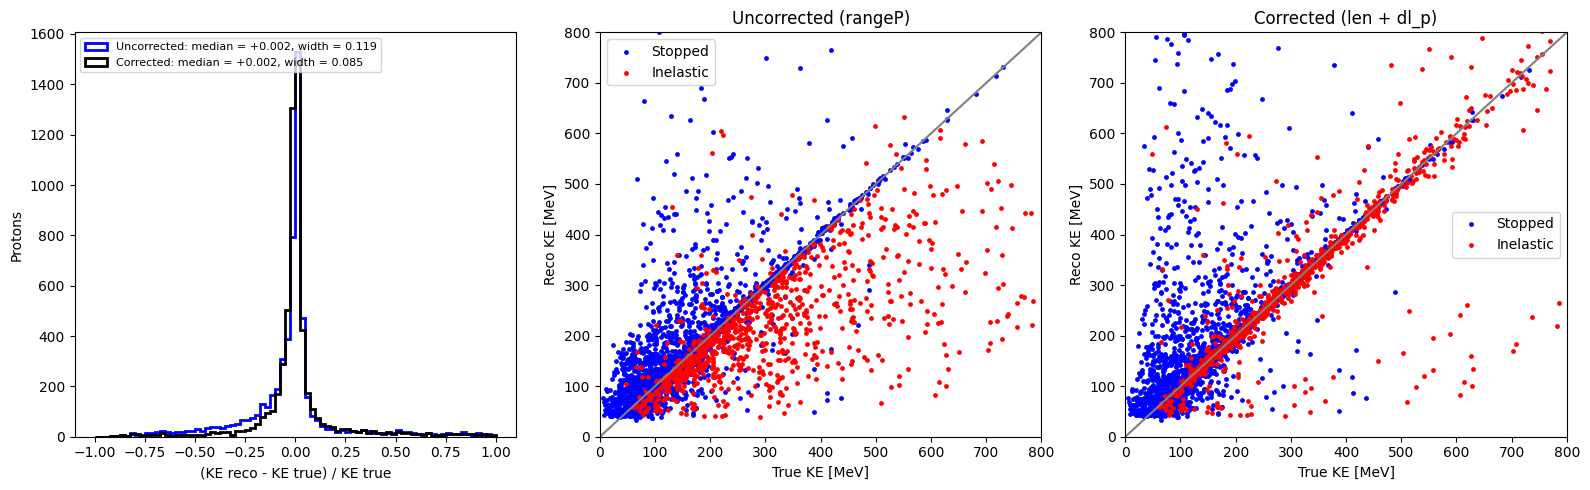

In [22]:
from makedf import llpid

# true protons that are contained in the TPC and have a likelihood fit
p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]

m_p = 0.938272  # GeV

# true KE
ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
ke_uncorr = (np.sqrt(p_range**2 + m_p**2) - m_p) * 1000  # MeV

# corrected: range = reco length + dl_p, turned into KE with the llpid range table
table = llpid._ke_table("p")
ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true proton ended
stopped = p_cont["pfp", "trk", "truth", "p", "end_process"] == 54   # hIoni: ranged out and stopped
inel    = p_cont["pfp", "trk", "truth", "p", "end_process"] == 7    # protonInelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Protons")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=6, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=6, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=6, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=6, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_p)")
ax[2].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1929644183.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]
/tmp/ipykernel_1150730/1929644183.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV
/tmp/ipykernel_1150730/1929644183.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
/tmp/ipykernel_1150730/1929644183.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/1929644183.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = (pi_cont["pfp", "trk", "truth", "p", "e

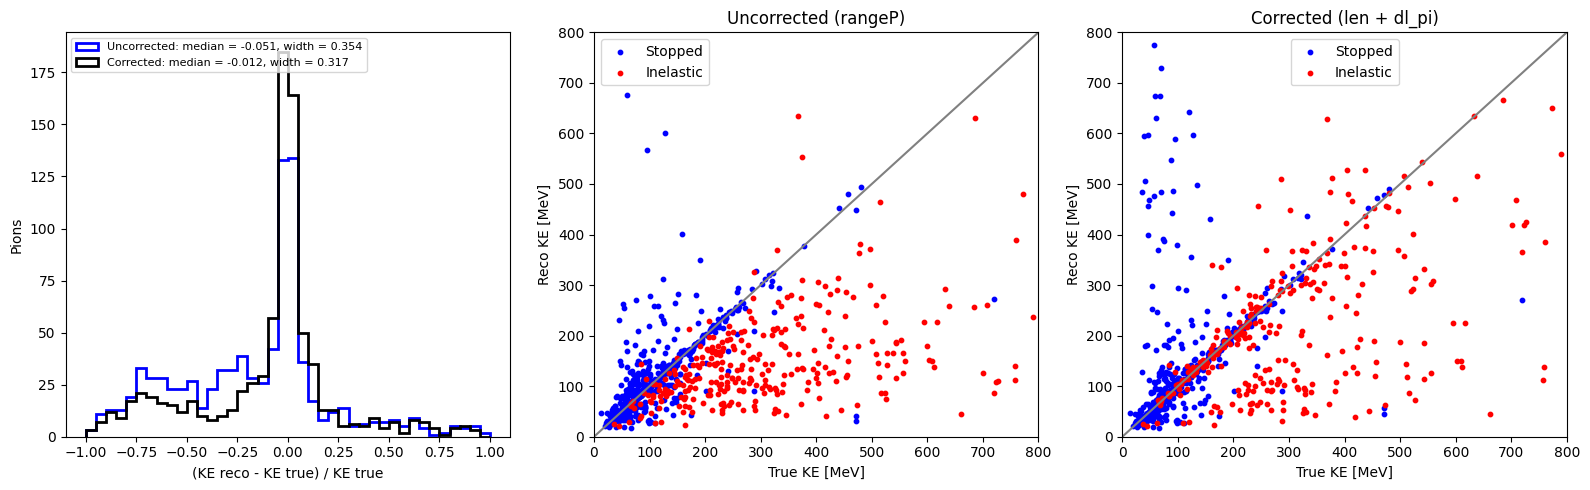

In [23]:
from makedf import llpid

# true pions that are contained in the TPC and have a likelihood fit
pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]

m_pi = 0.13957039  # GeV

# true KE
ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
ke_uncorr = (np.sqrt(p_range**2 + m_pi**2) - m_pi) * 1000  # MeV

# corrected: range = reco length + dl_pi, turned into KE with the llpid range table
table = llpid._ke_table("pi")
ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true pion ended
stopped = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 3) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 45)   # Decay or CaptureAtRest: stopped
inel    = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 9) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 10)   # pi+/pi- Inelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Pions")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=10, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=10, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=10, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=10, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_pi)")
ax[2].legend()

plt.tight_layout()
plt.show()


# Run on Gen 2 Analysis Full Run 1 MC + Fixed Dev Sample

Run only once to process all the files

In [1]:
import glob, os, time
from multiprocessing import Pool
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DFS = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/"         # grid outputs
SKIM = "/exp/sbnd/data/users/maxd/outputDF/llpid_skim/"          # skimmed files


In [2]:
PART_SIZE = 1000   # grid output files per skim file

# grid output directories per sample (original run + reruns of the missing jobs)
SAMPLES = {
    "mc":      ["2026_10_26_092752__Full_MC_LLPID_run1gen2",         "*__Full_MC_LLPID_run1gen2_redo"],
    "offbeam": ["2026_10_26_161014__Full_Offbeam_LLPID_run1gen2",    "*__Full_Offbeam_LLPID_run1gen2_redo"],
    "data":    ["2026_10_23_150629__Full_Data_LLPID_run1gen2_fixed", "*__Full_Data_LLPID_run1gen2_fixed_redo"],
}

# columns to keep: every column whose name starts with one of these
KEEP = [
    ("slc", "is_clear_cosmic"), ("slc", "nu_score"), ("slc", "vertex"), ("slc", "opt0", "score"),
    ("slc", "tmatch"), ("slc", "truth", "pdg"), ("slc", "truth", "iscc"), ("slc", "truth", "E"),
    ("pfp", "trackScore"), ("pfp", "dist_to_vertex"), ("pfp", "parent_is_primary"),
    ("pfp", "trk", "len"), ("pfp", "trk", "start"), ("pfp", "trk", "end"), ("pfp", "trk", "dir"),
    ("pfp", "trk", "chi2pid"), ("pfp", "trk", "rangeP"), ("pfp", "trk", "mcsP"),
    ("pfp", "trk", "llpid"),
    ("pfp", "trk", "truth", "p", "pdg"), ("pfp", "trk", "truth", "p", "cont_tpc"),
    ("pfp", "trk", "truth", "p", "startE"), ("pfp", "trk", "truth", "p", "end_process"),
    ("pfp", "trk", "truth", "p", "length"), ("pfp", "trk", "truth", "p", "interaction_id"),
]

def skim(f):
    hdr = pd.read_hdf(f, "hdr_0")
    pot = pd.read_hdf(f, "pot_0")
    histpot = pd.read_hdf(f, "histpotdf_0")
    evt = pd.read_hdf(f, "evt_0")

    # drop slices pandora flags as clear cosmics
    evt = evt[evt["slc", "is_clear_cosmic"] == 0]
    # MC: keep only slices matched to a neutrino, the cosmics come from the offbeam sample
    if hdr["ismc"].any():
        evt = evt[evt["slc", "tmatch", "idx"] >= 0]

    cols = [c for c in evt.columns if any(c[:len(k)] == k for k in KEEP) and c[3] != "version"]
    evt = evt[cols]
    floats = evt.columns[evt.dtypes == np.float64]
    evt[floats] = evt[floats].astype(np.float32)

    norm = {"file": f,
            "mc_pot": histpot["TotalPOT"].sum(),
            "bnb_pot": pot["TOR875"].sum(),
            "bnb_gates": len(pot),
            "offbeam_gates": hdr["noffbeambnb"].sum(),
            "n_events": len(hdr)}
    return evt, norm

def make_skim(sample):
    files = sorted(f for d in SAMPLES[sample] for f in glob.glob(DFS + d + "/*.df"))
    os.makedirs(SKIM, exist_ok=True)
    print(f"{sample}: {len(files)} files", flush=True)

    for part, start in enumerate(range(0, len(files), PART_SIZE)):
        t = time.time()
        with Pool(4) as p:
            out = p.map(skim, files[start:start + PART_SIZE], chunksize=10)

        # the 'file' index level makes (file, __ntuple, entry, slc, pfp) unique across files
        evt = pd.concat([o[0] for o in out], keys=range(start, start + len(out)), names=["file"])
        norm = pd.DataFrame([o[1] for o in out])

        outfile = SKIM + f"llpid_skim_{sample}_{part:02d}.h5"
        evt.to_hdf(outfile, key="evt", mode="w")
        norm.to_hdf(outfile, key="norm")
        print(f"wrote {outfile}: {len(out)} files, {len(evt)} rows, {time.time() - t:.0f} s", flush=True)


The next 3 lines will skim the entirety of the processed files skimming pertinent information; Only needs to be run once per set of cuts.

In [3]:
make_skim("data")


data: 1751 files
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_00.h5: 1000 files, 191630 rows, 95 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_01.h5: 751 files, 143563 rows, 70 s


In [4]:
make_skim("offbeam")


offbeam: 9998 files
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_00.h5: 1000 files, 732644 rows, 104 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_01.h5: 1000 files, 697330 rows, 107 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_02.h5: 1000 files, 717518 rows, 103 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_03.h5: 1000 files, 689750 rows, 110 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_04.h5: 1000 files, 715653 rows, 108 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_05.h5: 1000 files, 728275 rows, 112 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_06.h5: 1000 files, 703001 rows, 116 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_07.h5: 1000 files, 735584 rows, 110 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_08.h5: 1000 files, 703007 rows, 110 s

In [3]:
make_skim("mc")


mc: 10000 files
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_00.h5: 1000 files, 1235088 rows, 224 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_01.h5: 1000 files, 1234822 rows, 206 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_02.h5: 1000 files, 1235216 rows, 172 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_03.h5: 1000 files, 1239541 rows, 241 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_04.h5: 1000 files, 1237913 rows, 198 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_05.h5: 1000 files, 1237085 rows, 189 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_06.h5: 1000 files, 1237530 rows, 239 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_07.h5: 1000 files, 1233386 rows, 207 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_08.h5: 1000 files, 1231881 rows, 192 s
wrote /exp/sbnd/data/users/maxd/outputD

Once ran, can load files from here

In [4]:
def load(sample, nparts=None):
    files = sorted(glob.glob(SKIM + f"llpid_skim_{sample}_*.h5"))[:nparts]
    evt = pd.concat([pd.read_hdf(f, "evt") for f in files])
    norm = pd.concat([pd.read_hdf(f, "norm") for f in files])
    print(f"{sample}: {len(files)} skim files, {len(norm)} grid files, {len(evt)} tracks")
    return evt, norm

data, data_norm = load("data")
offbeam, offbeam_norm = load("offbeam", nparts=1)
mc, mc_norm = load("mc", nparts=1)


data: 2 skim files, 1751 grid files, 335193 tracks
offbeam: 1 skim files, 1000 grid files, 732644 tracks
mc: 1 skim files, 1000 grid files, 1235088 tracks


In [5]:
bnbGates = data_norm["bnb_gates"].sum()
n_events_bnb = data_norm["n_events"].sum()
offbeamGates = offbeam_norm["offbeam_gates"].sum()
n_events_offbeam = offbeam_norm["n_events"].sum()
print("BNB Gates:", bnbGates, " n_events_bnb:", n_events_bnb, " OffBeam Gates:", offbeamGates, " n_events_offbeam:", n_events_offbeam)

p_trig_data = n_events_bnb / bnbGates
p_trig_offbeam = n_events_offbeam / offbeamGates
f_factor = (p_trig_data - p_trig_offbeam) / (1 - p_trig_offbeam)
print("Fudge factor:", f_factor)

offbeam_scale = (1 - f_factor) * bnbGates / offbeamGates
print("Offbeam scale:", offbeam_scale)

pot = data_norm["bnb_pot"].sum()
print("Data POT:", pot)

mc_pot = mc_norm["mc_pot"].sum()
mc_scale = pot / mc_pot
print("MC POT:", mc_pot, " MC Scale Factor:", mc_scale)


BNB Gates: 925080  n_events_bnb: 86686  OffBeam Gates: 11794018.0  n_events_offbeam: 232558
Fudge factor: 0.07547645649592113
Offbeam scale: 0.07251627389620342
Data POT: 4.4515004e+18
MC POT: 5.410101998685053e+19  MC Scale Factor: 0.08228126511259701


In [ ]:
LL  = lambda df, name: df["pfp", "trk", "llpid", name]
CHI = lambda df, name: df["pfp", "trk", "chi2pid", "I2", name]

def contained(df, margin=10):
    ok = True
    for end in ["start", "end"]:
        x, y, z = df["pfp", "trk", end, "x"], df["pfp", "trk", end, "y"], df["pfp", "trk", end, "z"]
        ok = ok & (np.abs(x) < 200 - margin) & (np.abs(y) < 200 - margin) & (z > margin) & (z < 500 - margin)
    return ok

def selection(df):
    vx, vy, vz = df["slc", "vertex", "x"], df["slc", "vertex", "y"], df["slc", "vertex", "z"]
    in_fv = (np.abs(vx) < 190) & (np.abs(vy) < 190) & (vz > 10) & (vz < 450)
    return (in_fv
            # & (df["slc", "nu_score"] > 0.5)
            & (df["pfp", "trackScore"] > 0.5)
            & (df["pfp", "trk", "len"] > 6)
            & contained(df)
            # & LL(df, "ell_mu").notna()
            # & (CHI(df, "pid_ndof") > 0)
            )

data_sel = data[selection(data)]
off_sel = offbeam[selection(offbeam)]
mc_sel = mc[selection(mc)]

pdg = np.abs(mc_sel["pfp", "trk", "truth", "p", "pdg"])
mc_cat = np.select([pdg == 13, pdg == 2212, pdg == 211], ["muon", "proton", "pion"], "other")
print(f"selected tracks: data {len(data_sel)}, offbeam {len(off_sel)} (x{offbeam_scale:.4f}), MC {len(mc_sel)} (x{mc_scale:.4f})")


selected tracks: data 23263, offbeam 8858 (x0.0725), MC 277699 (x0.0823)


In [7]:
CATS = ["muon", "proton", "pion", "other"]
COLORS = ["tab:red", "tab:blue", "tab:green", "tab:gray", "tab:purple"]

def plot_var(f, bins, xlabel, logy=False):
    fig, (ax, rax) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    centers = (bins[1:] + bins[:-1]) / 2

    mc_vals = f(mc_sel)
    stack = [np.histogram(mc_vals[mc_cat == c], bins)[0] * mc_scale for c in CATS]
    stack.append(np.histogram(f(off_sel), bins)[0] * offbeam_scale)
    labels = [f"MC {c}" for c in CATS] + ["cosmic (offbeam)"]
    ax.hist([centers] * len(stack), bins, weights=stack, stacked=True, color=COLORS,
            label=[f"{l}: {s.sum():.0f}" for l, s in zip(labels, stack)])

    d = np.histogram(f(data_sel), bins)[0]
    ax.errorbar(centers, d, yerr=np.sqrt(d), fmt="ko", ms=4, label=f"data: {d.sum()}")

    pred = np.sum(stack, axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        rax.errorbar(centers, d / pred, yerr=np.sqrt(d) / pred, fmt="ko", ms=4)
    rax.axhline(1, color="gray", ls="--")
    rax.set_ylim(0.5, 1.5)
    rax.set_ylabel("data / pred")
    rax.set_xlabel(xlabel)
    ax.set_ylabel("tracks")
    ax.legend(fontsize=8)
    if logy:
        ax.set_yscale("log")
    plt.show()


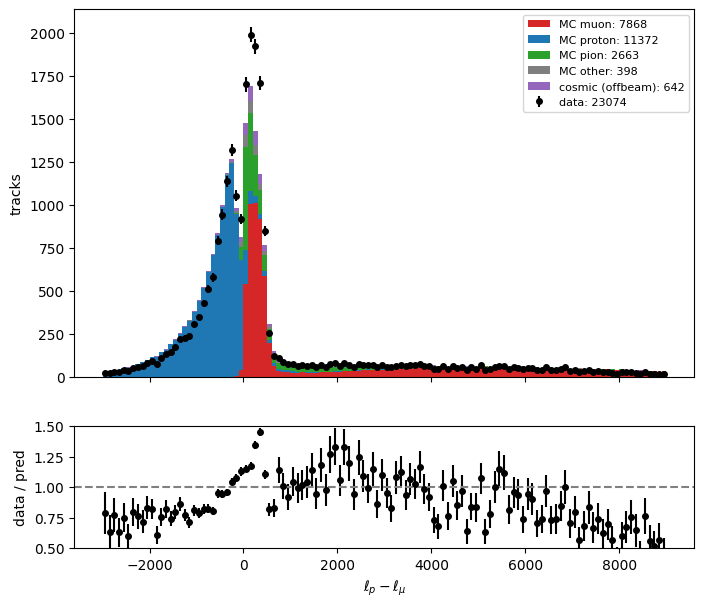

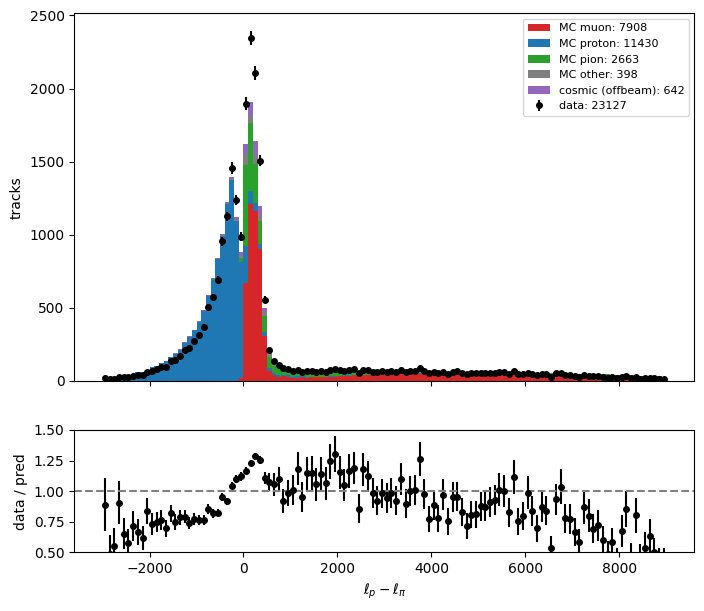

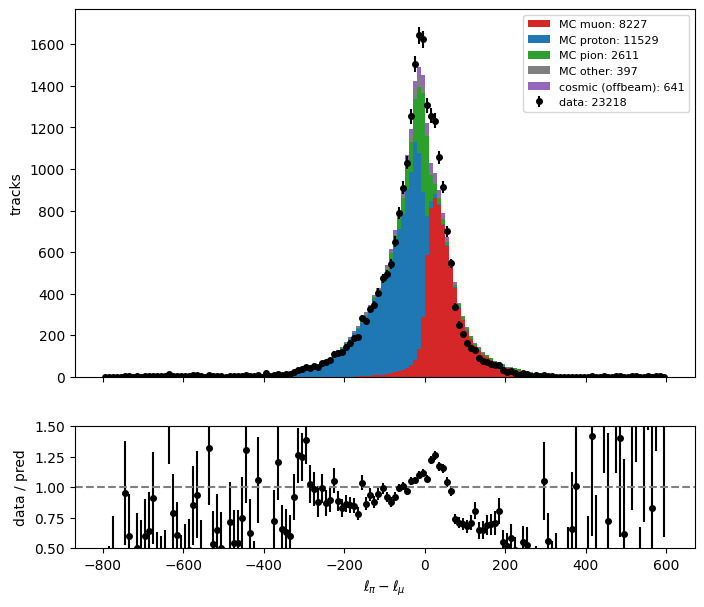

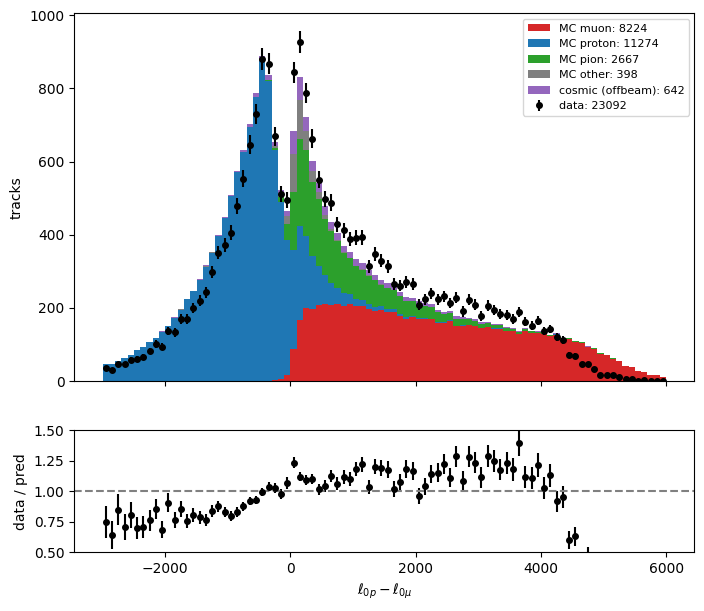

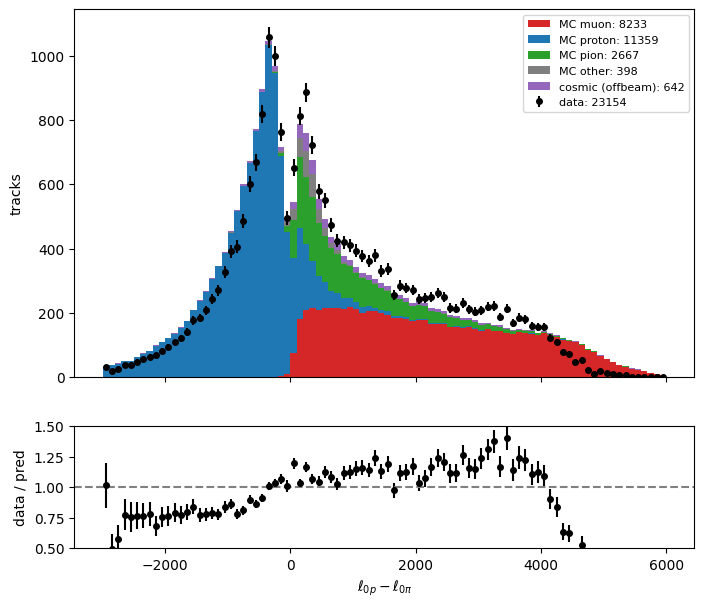

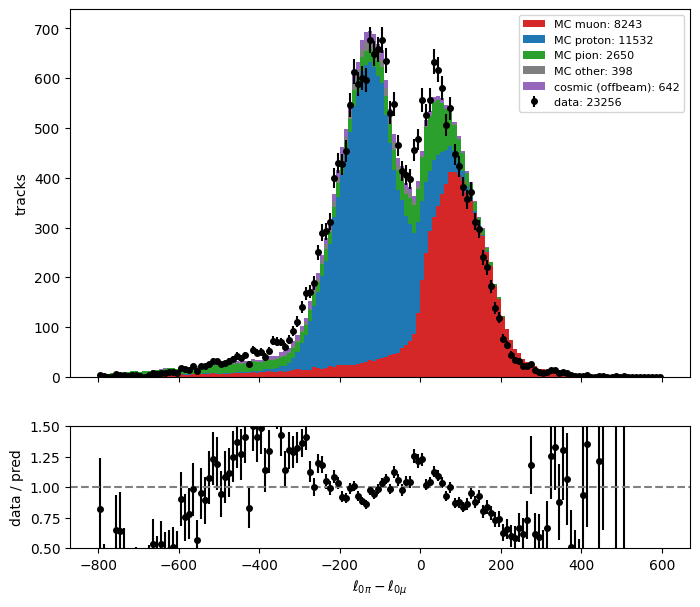

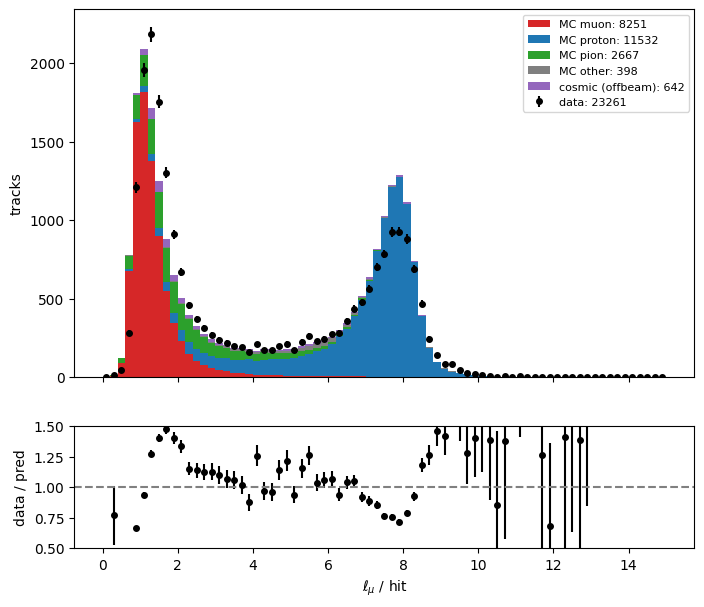

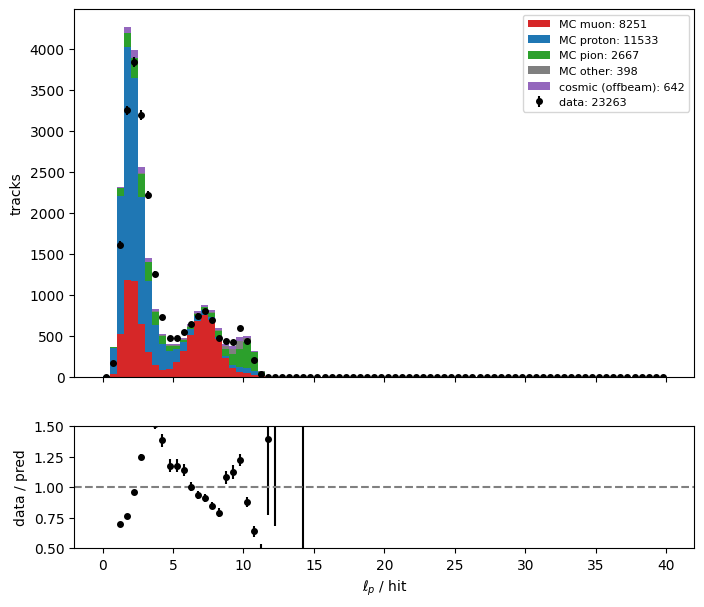

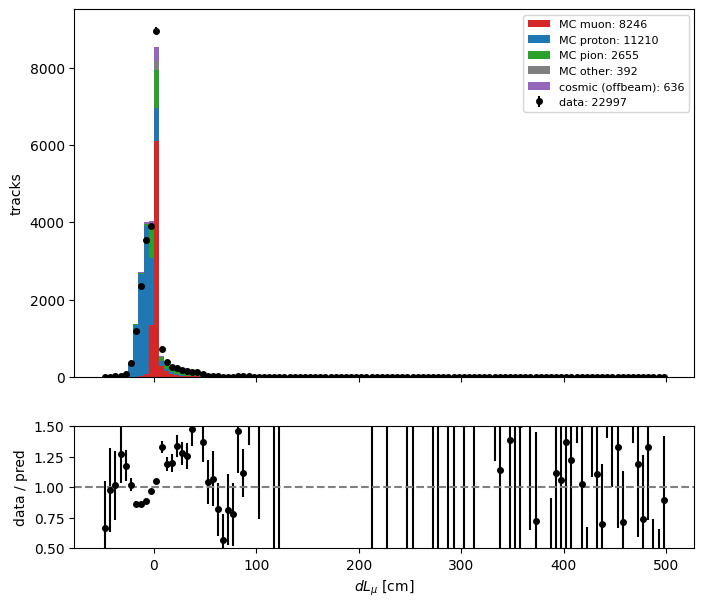

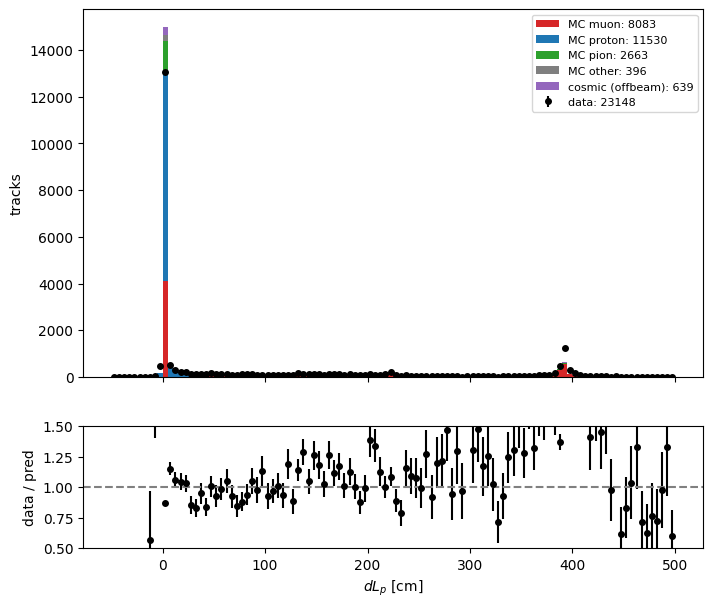

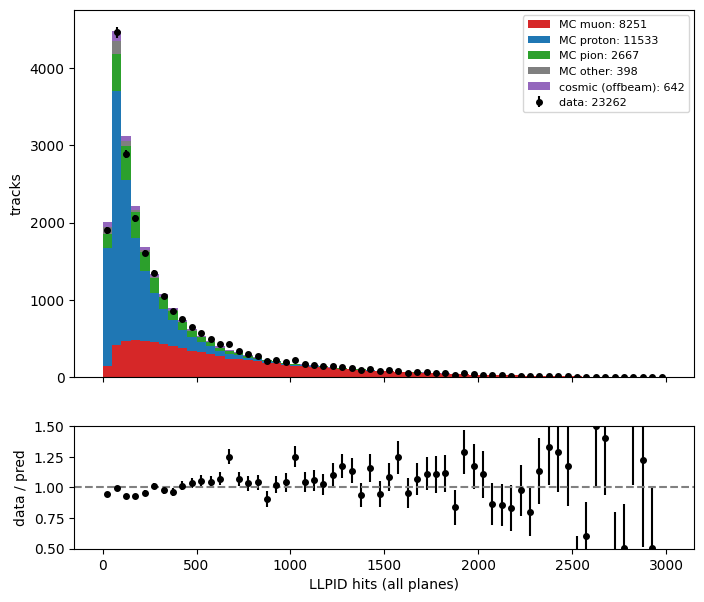

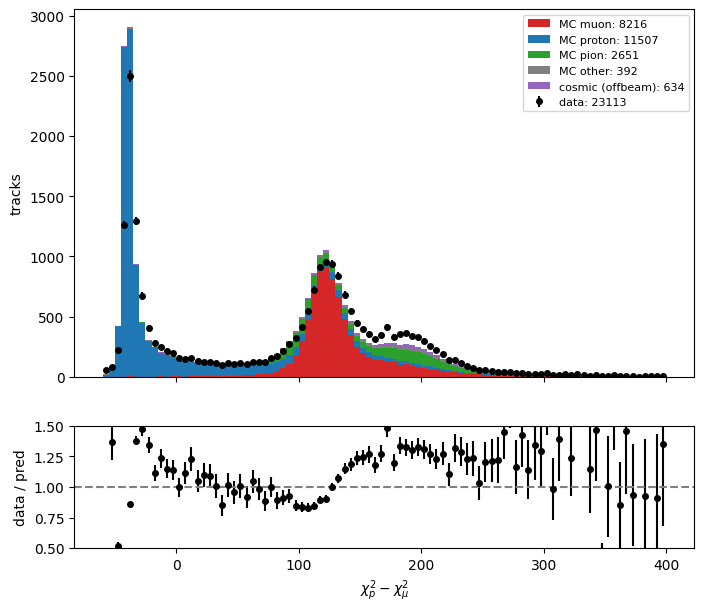

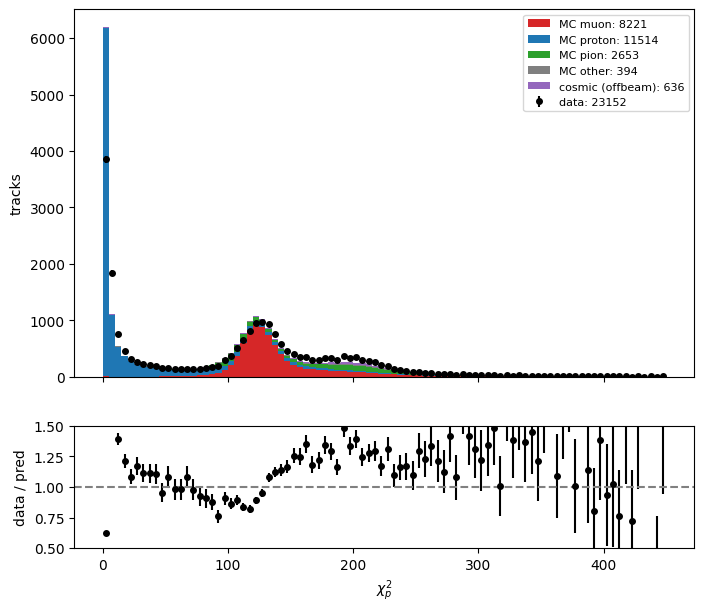

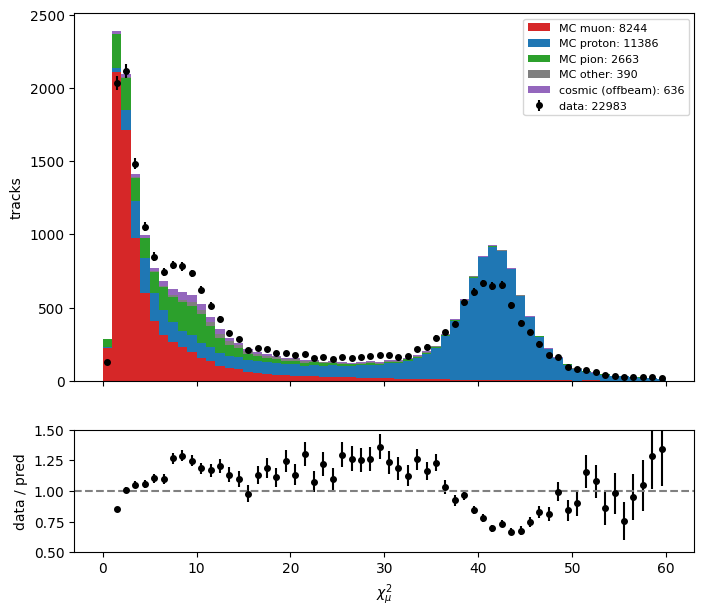

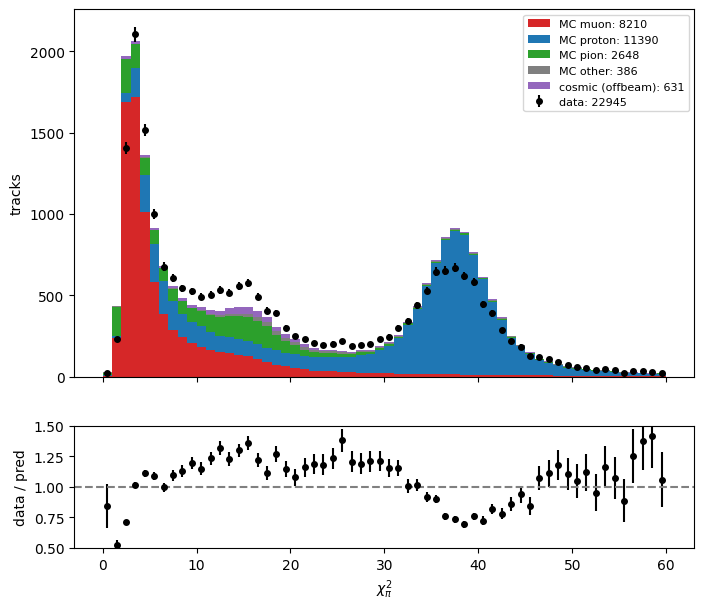

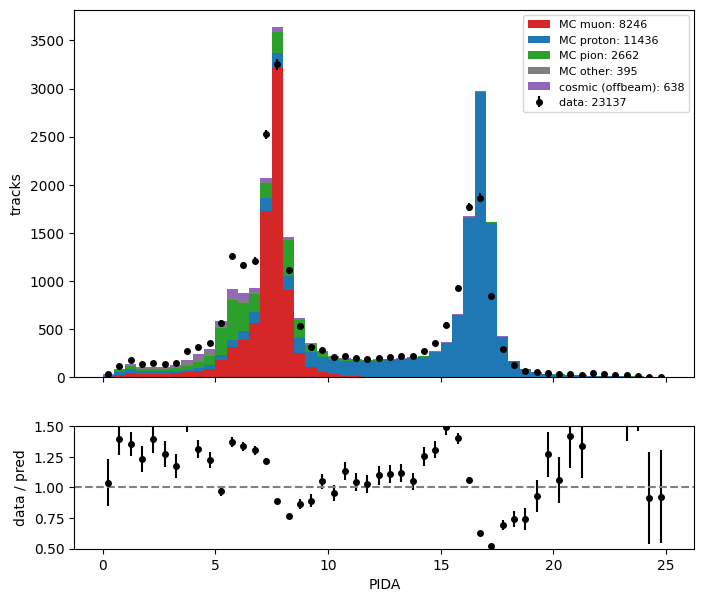

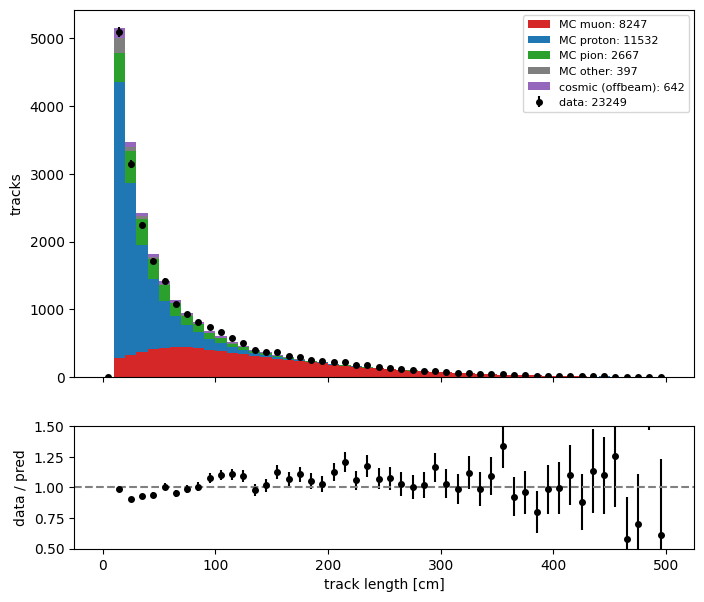

In [8]:
VARS = [
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-3000, 9000, 121), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_pi"),       np.linspace(-3000, 9000, 121), r"$\ell_p - \ell_\pi$"),
    (lambda d: LL(d, "ell_pi") - LL(d, "ell_mu"),      np.linspace(-800, 600, 141),   r"$\ell_\pi - \ell_\mu$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-3000, 6000, 91),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_pi"),     np.linspace(-3000, 6000, 91),  r"$\ell_{0p} - \ell_{0\pi}$"),
    (lambda d: LL(d, "ell0_pi") - LL(d, "ell0_mu"),    np.linspace(-800, 600, 141),   r"$\ell_{0\pi} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell_mu") / LL(d, "nhits_mu"),    np.linspace(0, 15, 76),        r"$\ell_\mu$ / hit"),
    (lambda d: LL(d, "ell_p") / LL(d, "nhits_p"),      np.linspace(0, 40, 81),        r"$\ell_p$ / hit"),
    (lambda d: LL(d, "dl_mu"),                         np.linspace(-50, 500, 111),    r"$dL_\mu$ [cm]"),
    (lambda d: LL(d, "dl_p"),                          np.linspace(-50, 500, 111),    r"$dL_p$ [cm]"),
    (lambda d: LL(d, "nhits_mu"),                      np.linspace(0, 3000, 61),      "LLPID hits (all planes)"),
    (lambda d: CHI(d, "chi2_proton") - CHI(d, "chi2_muon"), np.linspace(-60, 400, 93), r"$\chi^2_p - \chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_proton"),                  np.linspace(0, 450, 91),       r"$\chi^2_p$"),
    (lambda d: CHI(d, "chi2_muon"),                    np.linspace(0, 60, 61),        r"$\chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_pion"),                    np.linspace(0, 60, 61),        r"$\chi^2_\pi$"),
    (lambda d: CHI(d, "pida"),                         np.linspace(0, 25, 51),        "PIDA"),
    (lambda d: d["pfp", "trk", "len"],                 np.linspace(0, 500, 51),       "track length [cm]"),
]
for f, bins, xlabel in VARS:
    plot_var(f, bins, xlabel)


true muons / pions / protons: 1003793 323871 1402904
p vs mu, Likelihood              : p efficiency at 1% / 2% / 5% mu mis-ID = 0.961 / 0.965 / 0.970
p vs mu, Likelihood (no rr corr) : p efficiency at 1% / 2% / 5% mu mis-ID = 0.900 / 0.914 / 0.942
p vs mu, Chi2                    : p efficiency at 1% / 2% / 5% mu mis-ID = 0.854 / 0.877 / 0.897
p vs pi, Likelihood              : p efficiency at 1% / 2% / 5% pi mis-ID = 0.943 / 0.949 / 0.955
p vs pi, Likelihood (no rr corr) : p efficiency at 1% / 2% / 5% pi mis-ID = 0.874 / 0.887 / 0.901
p vs pi, Chi2                    : p efficiency at 1% / 2% / 5% pi mis-ID = 0.787 / 0.828 / 0.865
mu vs pi, Likelihood              : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.002 / 0.004 / 0.050
mu vs pi, Likelihood (no rr corr) : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.183 / 0.253 / 0.388
mu vs pi, Chi2                    : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.008 / 0.015 / 0.034


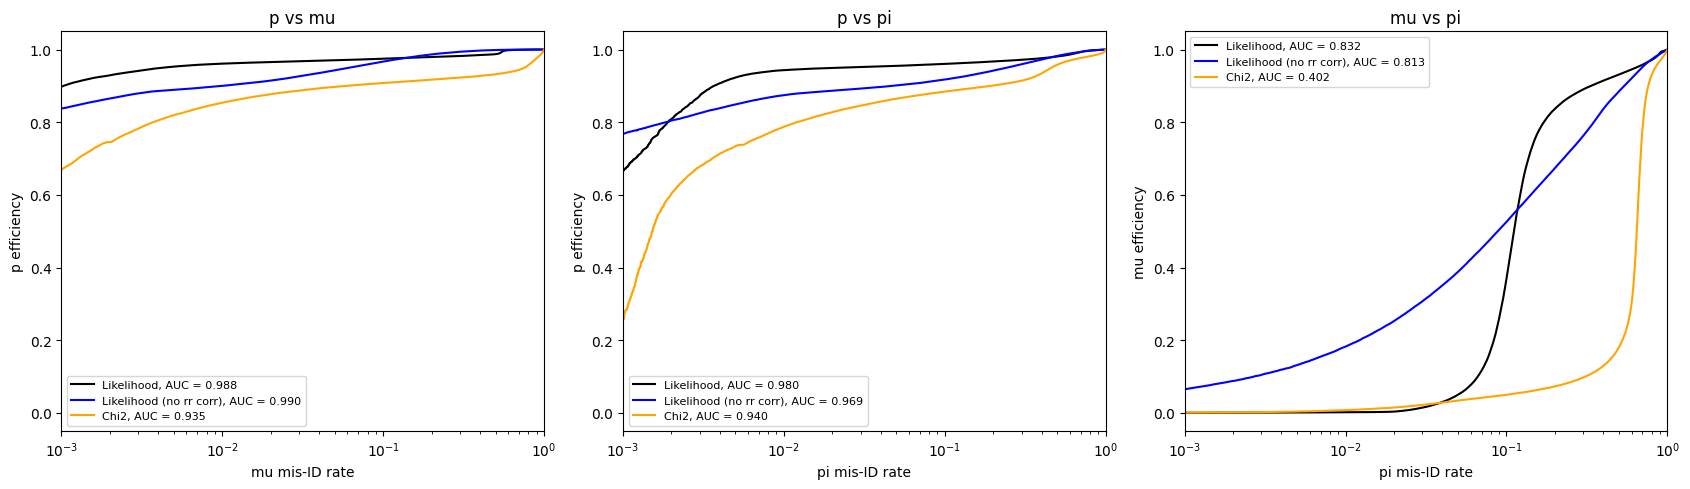

In [9]:
perf = []
for f in sorted(glob.glob(SKIM + "llpid_skim_mc_*.h5")):
    d = pd.read_hdf(f, "evt")
    d = d[selection(d)]
    perf.append(d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])])
perf = pd.concat(perf)
true = np.abs(perf["pfp", "trk", "truth", "p", "pdg"]).to_numpy()
print("true muons / pions / protons:", np.sum(true == 13), np.sum(true == 211), np.sum(true == 2212))

def roc(sig, bkg):
    """signal efficiency vs background mis-ID when selecting score <= cut"""
    sig, bkg = np.sort(sig[~np.isnan(sig)]), np.sort(bkg[~np.isnan(bkg)])
    cut = np.quantile(np.concatenate([sig, bkg]), np.linspace(0, 1, 2001))
    return np.searchsorted(bkg, cut, side="right") / len(bkg), np.searchsorted(sig, cut, side="right") / len(sig)

PDG = {"mu": 13, "pi": 211, "p": 2212}
CHI_NAME = {"mu": "chi2_muon", "pi": "chi2_pion", "p": "chi2_proton"}
SCORES = {
    "Likelihood":              lambda d, a, b: LL(d, "ell_" + a) - LL(d, "ell_" + b),
    "Likelihood (no rr corr)": lambda d, a, b: LL(d, "ell0_" + a) - LL(d, "ell0_" + b),
    "Chi2":                    lambda d, a, b: CHI(d, CHI_NAME[a]) - CHI(d, CHI_NAME[b]),
}

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for i, (a, b) in enumerate([("p", "mu"), ("p", "pi"), ("mu", "pi")]):
    for (name, score), color in zip(SCORES.items(), ["black", "blue", "orange"]):
        s = score(perf, a, b).to_numpy()
        bkg_eff, sig_eff = roc(s[true == PDG[a]], s[true == PDG[b]])
        ax[i].plot(bkg_eff, sig_eff, color=color, label=f"{name}, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
        print(f"{a} vs {b}, {name:24s}: {a} efficiency at 1% / 2% / 5% {b} mis-ID = "
              + " / ".join(f"{np.interp(x, bkg_eff, sig_eff):.3f}" for x in [0.01, 0.02, 0.05]))
    ax[i].set(title=f"{a} vs {b}", xlabel=f"{b} mis-ID rate", ylabel=f"{a} efficiency", xscale="log", xlim=(1e-3, 1))
    ax[i].legend(fontsize=8)
plt.tight_layout()
plt.show()


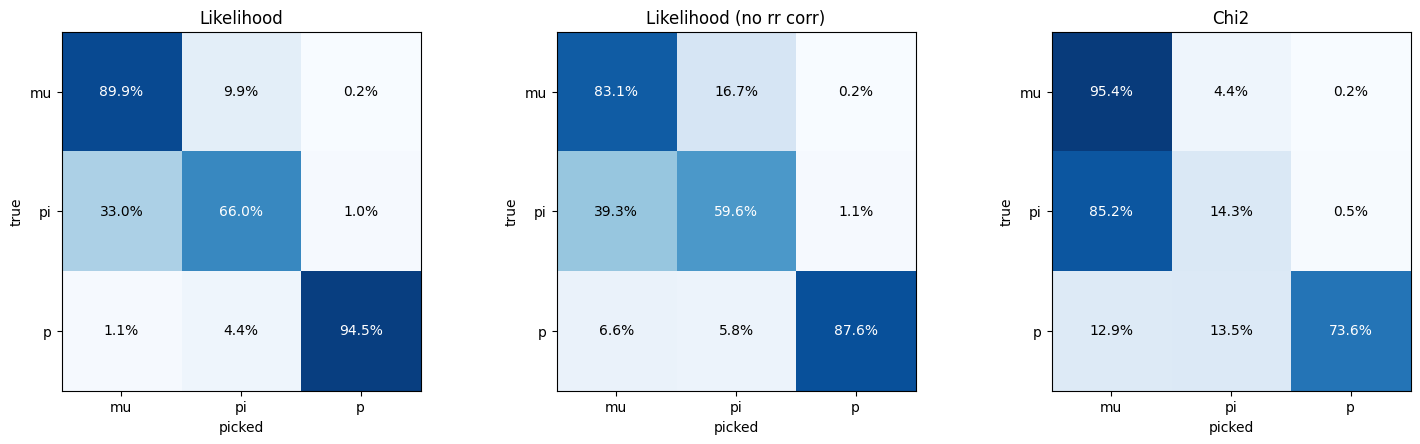

In [10]:
HYPS = ["mu", "pi", "p"]
best = {
    "Likelihood":              np.argmin(np.column_stack([LL(perf, "ell_" + h) for h in HYPS]), axis=1),
    "Likelihood (no rr corr)": np.argmin(np.column_stack([LL(perf, "ell0_" + h) for h in HYPS]), axis=1),
    "Chi2":                    np.argmin(np.column_stack([CHI(perf, CHI_NAME[h]) for h in HYPS]), axis=1),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (name, pick) in enumerate(best.items()):
    mat = np.array([[np.mean(pick[true == PDG[t]] == j) for j in range(3)] for t in HYPS])
    ax[k].imshow(mat, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax[k].text(j, i, f"{100 * mat[i, j]:.1f}%", ha="center", va="center", color="white" if mat[i, j] > 0.5 else "black")
    ax[k].set(title=name, xticks=range(3), yticks=range(3), xticklabels=HYPS, yticklabels=HYPS, xlabel="picked", ylabel="true")
plt.tight_layout()
plt.show()
